> # EDA 

In [ ]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Style configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 12

In [ ]:
# Load clean dataset
df = pd.read_csv("../data/processed/dataset_clean.csv")

print(f"Dataset loaded successfully")
print(f" Shape : {df.shape}")
print(f"\n First rows :")
df.head()

In [ ]:
# Basic dataset overview

print("Dataset Shape")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nData Types")
print(df.dtypes)

print("\nMissing Values")
print(df.isnull().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

In [ ]:
# #  Check real duplicates (same text only)
real_duplicates = df[df.duplicated(subset=["text"], keep=False)]
print(f" Real duplicates (same text) : {len(real_duplicates)}")
print(real_duplicates[["text", "sentiment", "language", "domain"]].head(10))

In [ ]:
# #  Remove real duplicates based on text only
before = len(df)
#f = df.drop_duplicates(subset=["text"], keep="first")
df = df.drop_duplicates(keep="first")
after = len(df)

print(f" Duplicates removed : {before - after}")
print(f" Rows remaining : {after}")
print(f"\n Sentiment distribution after dedup :")
print(df["sentiment"].value_counts())

 Duplicates removed : 72
 Rows remaining : 4199

 Sentiment distribution after dedup :
sentiment
neutral      1504
positive     1381
negative     1296
surprised       8
anxious         6
worried         4
Name: count, dtype: int64


In [ ]:
# Merge minority classes into 'negative'
df['sentiment'] = df['sentiment'].replace({
    'surprised': 'negative',
    'anxious': 'negative',
    'worried': 'negative'
})

# Verify the new distribution
print("Distribution after merge:")
print(df['sentiment'].value_counts())
print(f"\nTotal: {len(df)} rows")

Distribution after merge:
sentiment
neutral     1504
positive    1381
negative    1314
Name: count, dtype: int64

Total: 4199 rows


In [ ]:
# Save the dataset
OUTPUT_PATH = Path("../data/processed/dataset_clean_EDA.csv")
df.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")
print(f"  dataset saved → {OUTPUT_PATH}")
print(f" Total rows : {len(df)}")

  dataset saved → ..\data\processed\dataset_clean_EDA.csv
 Total rows : 4199


## visualizations

In [ ]:
#  Load the new dataset dataset_clean_EDA.csv

data = pd.read_csv("../data/processed/dataset_clean_EDA.csv")
print(f" Dataset loaded : {data.shape}")

 Dataset loaded : (4199, 6)


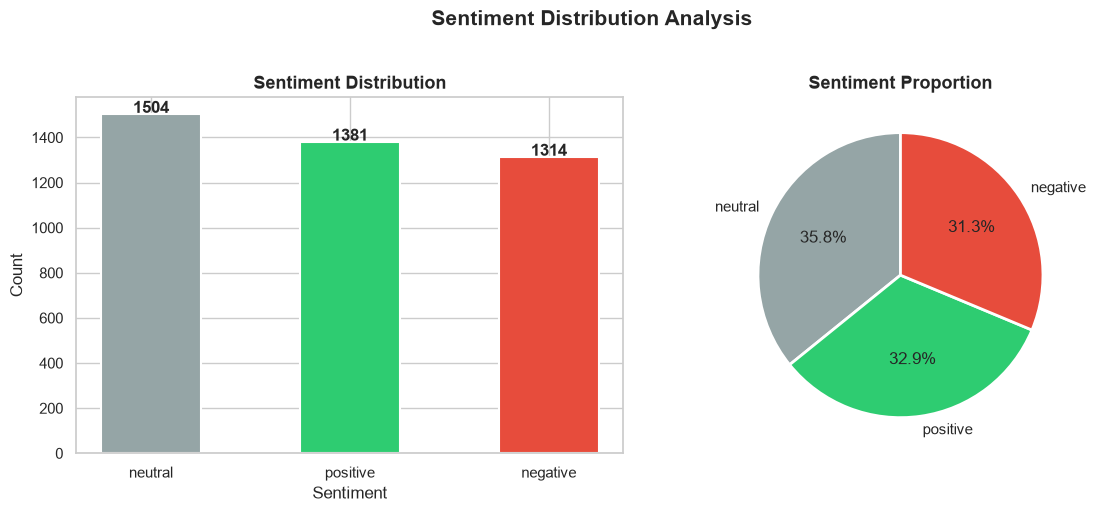

In [ ]:
#  Visualization 1 : Sentiment Distribution
fig, axes = plt.subplots(1, 2, figsize=(12,5))

colors = {
    "positive": "#2ecc71",
    "negative": "#e74c3c",
    "neutral" : "#95a5a6"
}
sentiment_counts = data["sentiment"].value_counts()

# Bar chart
bars = axes[0].bar(
    sentiment_counts.index,
    sentiment_counts.values,
    color=[colors[s] for s in sentiment_counts.index],
    edgecolor="white", linewidth=1.5, width=0.5
)
axes[0].set_title("Sentiment Distribution", fontweight="bold", fontsize=13)
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Count")
for bar, v in zip(bars, sentiment_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 v + 5, str(v), ha="center", fontweight="bold")

# Pie chart
axes[1].pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    colors=[colors[s] for s in sentiment_counts.index],
    autopct="%1.1f%%", startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
axes[1].set_title("Sentiment Proportion", fontweight="bold", fontsize=13)

plt.suptitle("Sentiment Distribution Analysis", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/viz1_sentiment_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

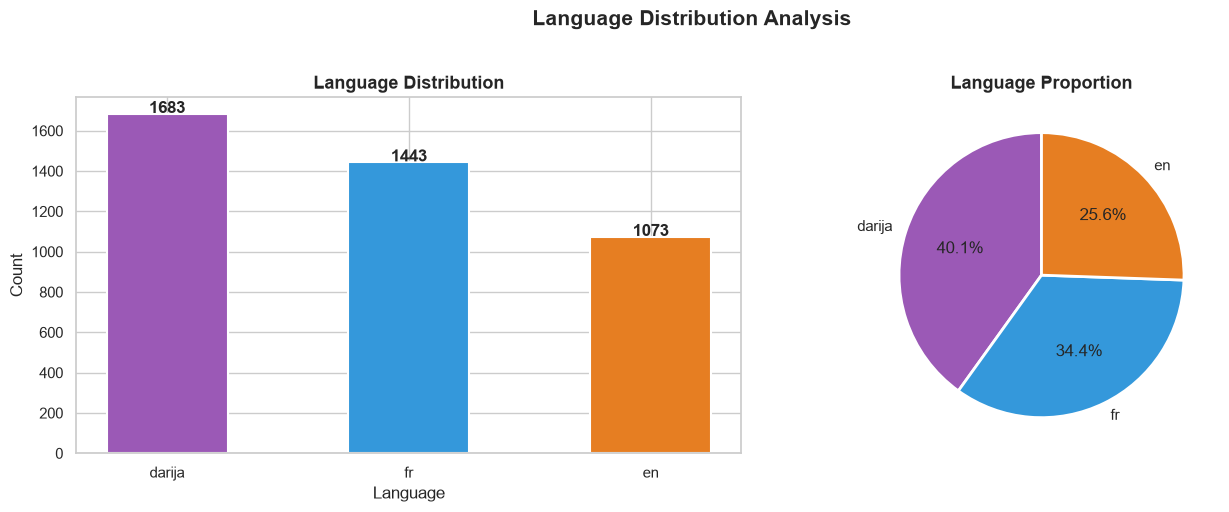

In [ ]:
#  Visualization 2 : Language Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

lang_colors = {
    "fr"    : "#3498db",
    "en"    : "#e67e22",
    "darija": "#9b59b6"
}
lang_counts = data["language"].value_counts()

# Bar chart
bars = axes[0].bar(
    lang_counts.index,
    lang_counts.values,
    color=[lang_colors[l] for l in lang_counts.index],
    edgecolor="white", linewidth=1.5, width=0.5
)
axes[0].set_title("Language Distribution", fontweight="bold", fontsize=13)
axes[0].set_xlabel("Language")
axes[0].set_ylabel("Count")
for bar, v in zip(bars, lang_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 v + 5, str(v), ha="center", fontweight="bold")

# Pie chart
axes[1].pie(
    lang_counts.values,
    labels=lang_counts.index,
    colors=[lang_colors[l] for l in lang_counts.index],
    autopct="%1.1f%%", startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
axes[1].set_title("Language Proportion", fontweight="bold", fontsize=13)

plt.suptitle("Language Distribution Analysis", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/viz2_language_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
print(data["language"].value_counts())
print(data["language"].unique())

language
darija    1683
fr        1443
en        1073
Name: count, dtype: int64
<StringArray>
['fr', 'en', 'darija']
Length: 3, dtype: str


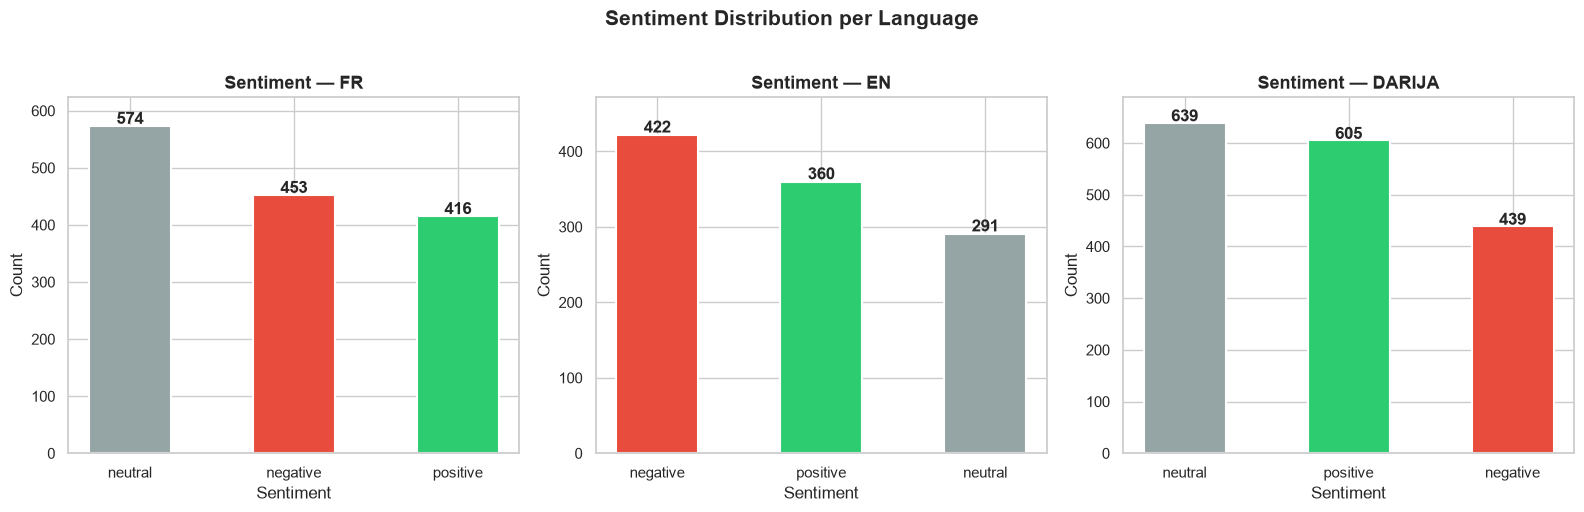

In [ ]:
#  Visualization 3 : Sentiment by Language
languages = ["fr", "en", "darija"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, lang in enumerate(languages):
    subset = data[data["language"] == lang]["sentiment"].value_counts()
    bars = axes[idx].bar(
        subset.index,
        subset.values,
        color=[colors[s] for s in subset.index],
        edgecolor="white", linewidth=1.5, width=0.5
    )
    axes[idx].set_title(f"Sentiment — {lang.upper()}", fontweight="bold", fontsize=13)
    axes[idx].set_xlabel("Sentiment")
    axes[idx].set_ylabel("Count")
    axes[idx].set_ylim(0, subset.values.max() + 50)
    for bar, v in zip(bars, subset.values):
        axes[idx].text(bar.get_x() + bar.get_width()/2,
                       v + 3, str(v), ha="center", fontweight="bold")

plt.suptitle("Sentiment Distribution per Language", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/viz3_sentiment_by_language.png", dpi=150, bbox_inches="tight")
plt.show()

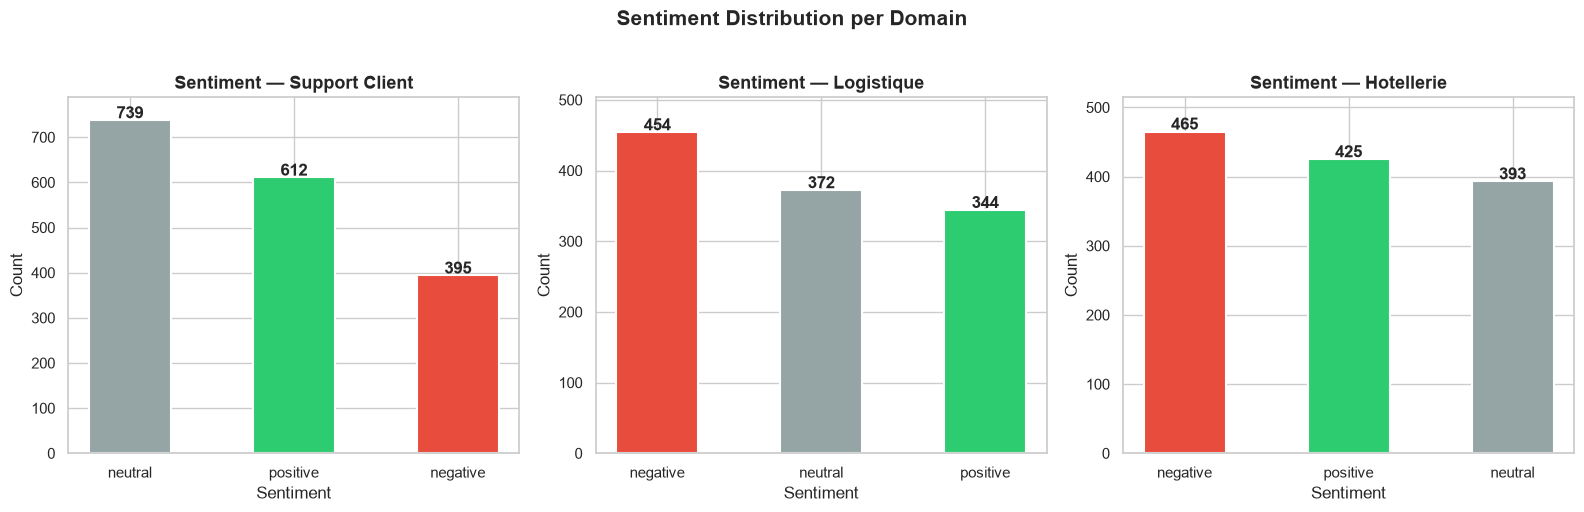

In [ ]:
#  Visualization 4 : Sentiment by Domain
domains = ["support_client", "logistique", "hotellerie"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

domain_titles = {
    "support_client": "Support Client",
    "logistique"    : "Logistique",
    "hotellerie"    : "Hotellerie"
}

for idx, domain in enumerate(domains):
    subset = data[data["domain"] == domain]["sentiment"].value_counts()
    bars = axes[idx].bar(
        subset.index,
        subset.values,
        color=[colors[s] for s in subset.index],
        edgecolor="white", linewidth=1.5, width=0.5
    )
    axes[idx].set_title(f"Sentiment — {domain_titles[domain]}",
                        fontweight="bold", fontsize=13)
    axes[idx].set_xlabel("Sentiment")
    axes[idx].set_ylabel("Count")
    axes[idx].set_ylim(0, subset.values.max() + 50)
    for bar, v in zip(bars, subset.values):
        axes[idx].text(bar.get_x() + bar.get_width()/2,
                       v + 3, str(v), ha="center", fontweight="bold")

plt.suptitle("Sentiment Distribution per Domain", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/viz4_sentiment_by_domain.png", dpi=150, bbox_inches="tight")
plt.show()

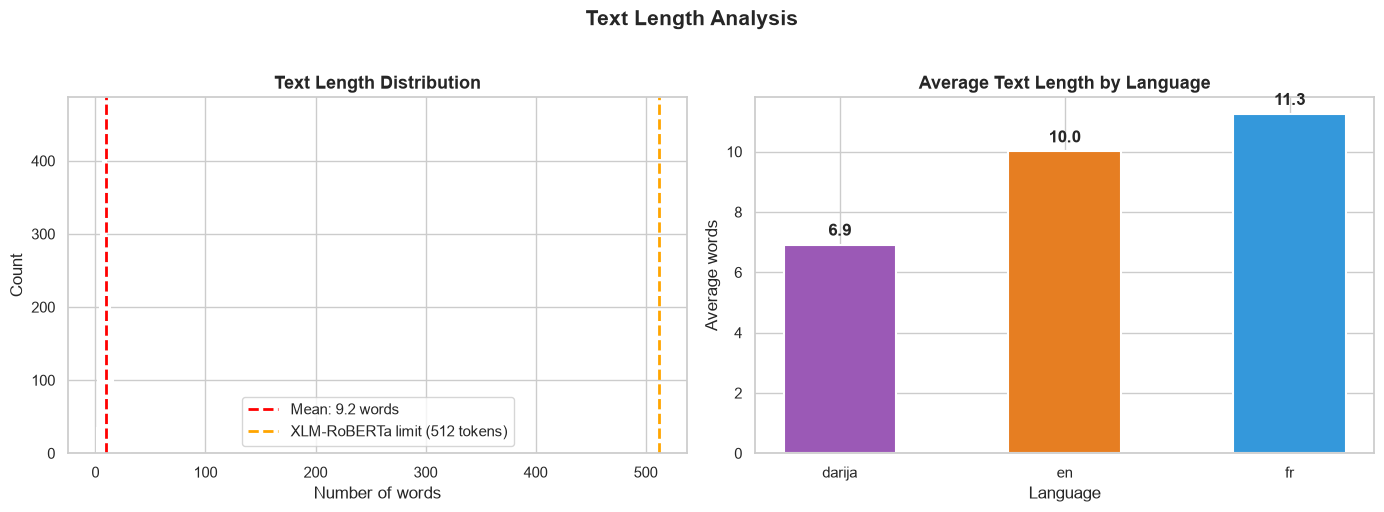


 Text length stats :
count    4199.00
mean        9.20
std         4.62
min         1.00
25%         6.00
50%         8.00
75%        12.00
max        31.00
Name: text_length, dtype: float64

Texts over 512 words : 0


In [ ]:
#  Visualization 5 : Text Length Distribution
data["text_length"] = data["text"].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall distribution
axes[0].hist(
    data["text_length"], bins=30,
    color="#3498db", edgecolor="white", linewidth=1.5
)
axes[0].axvline(
    data["text_length"].mean(),
    color="red", linestyle="--", linewidth=2,
    label=f'Mean: {data["text_length"].mean():.1f} words'
)
axes[0].axvline(
    512, color="orange", linestyle="--", linewidth=2,
    label="XLM-RoBERTa limit (512 tokens)"
)
axes[0].set_title("Text Length Distribution", fontweight="bold", fontsize=13)
axes[0].set_xlabel("Number of words")
axes[0].set_ylabel("Count")
axes[0].legend()

# By language
lang_lengths = data.groupby("language")["text_length"].mean()
bars = axes[1].bar(
    lang_lengths.index,
    lang_lengths.values,
    color=[lang_colors[l] for l in lang_lengths.index],
    edgecolor="white", linewidth=1.5, width=0.5
)
axes[1].set_title("Average Text Length by Language", fontweight="bold", fontsize=13)
axes[1].set_xlabel("Language")
axes[1].set_ylabel("Average words")
for bar, v in zip(bars, lang_lengths.values):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 v + 0.3, f"{v:.1f}", ha="center", fontweight="bold")

plt.suptitle("Text Length Analysis", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/viz5_text_length.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n Text length stats :")
print(data["text_length"].describe().round(2))   
print(f"\nTexts over 512 words : {(data['text_length'] > 512).sum()}")

## Text Length Analysis

| Statistic | Value |
|------------|------:|
| Mean | 9.2 words |
| Median | 8 words |
| Standard Deviation | 4.62 |
| Min / Max | 1 / 31 words |
| Texts > 512 words | 0 |

The texts are very short (chat/support-style conversational messages).

**No text exceeds the 512-token limit of XLM-RoBERTa**, so **no truncation will be required during tokenization**.

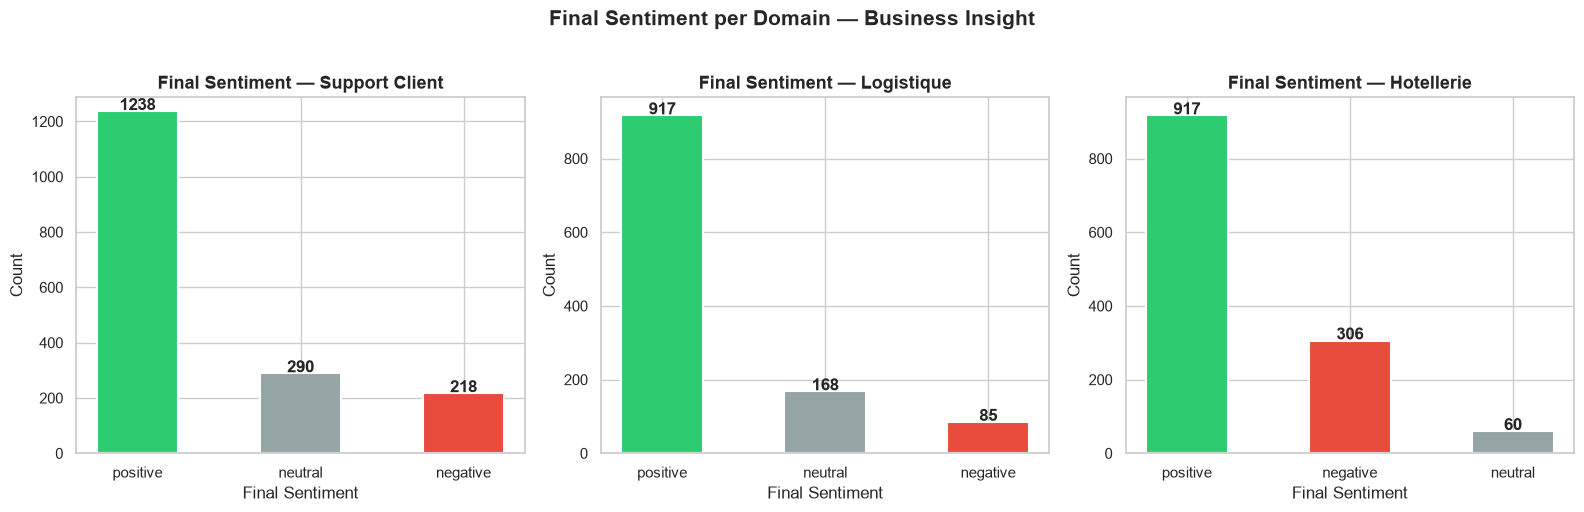

In [ ]:
#  Visualization 6 : Final Sentiment by Domain (Business Insight)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

final_colors = {
    "positive": "#2ecc71",
    "negative": "#e74c3c",
    "neutral" : "#95a5a6"
}

for idx, domain in enumerate(domains):
    subset = data[
        data["domain"] == domain
    ]["final_sentiment"].value_counts()

    bars = axes[idx].bar(
        subset.index,
        subset.values,
        color=[final_colors.get(s, "#bdc3c7") for s in subset.index],
        edgecolor="white", linewidth=1.5, width=0.5
    )
    axes[idx].set_title(f"Final Sentiment — {domain_titles[domain]}",
                        fontweight="bold", fontsize=13)
    axes[idx].set_xlabel("Final Sentiment")
    axes[idx].set_ylabel("Count")
    axes[idx].set_ylim(0, subset.values.max() + 50)
    for bar, v in zip(bars, subset.values):
        axes[idx].text(bar.get_x() + bar.get_width()/2,
                       v + 3, str(v), ha="center", fontweight="bold")

plt.suptitle("Final Sentiment per Domain — Business Insight",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../data/processed/viz6_final_sentiment_by_domain.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# EDA final summary

print("EDA Final Summary")

print(f"\nTotal messages: {len(data)}")
print(f"Number of languages: {data['language'].nunique()}")
print(f"Number of domains: {data['domain'].nunique()}")
print(f"Number of sentiment classes: {data['sentiment'].nunique()}")
print(f"Average text length: {data['text_length'].mean():.1f} words")
print(f"Maximum text length: {data['text_length'].max()} words")
print(f"Texts longer than 512 words: {(data['text_length'] > 512).sum()}")

print("\nSentiment Distribution:")
print(data["sentiment"].value_counts())

print("\nLanguage Distribution:")
print(data["language"].value_counts())

print("\nDomain Distribution:")
print(data["domain"].value_counts())

EDA Final Summary

Total messages: 4199
Number of languages: 3
Number of domains: 3
Number of sentiment classes: 3
Average text length: 9.2 words
Maximum text length: 31 words
Texts longer than 512 words: 0

Sentiment Distribution:
sentiment
neutral     1504
positive    1381
negative    1314
Name: count, dtype: int64

Language Distribution:
language
darija    1683
fr        1443
en        1073
Name: count, dtype: int64

Domain Distribution:
domain
support_client    1746
hotellerie        1283
logistique        1170
Name: count, dtype: int64


In [ ]:
%pip install scikit-learn

In [ ]:
# spplit the data : 80% train , 20% test
from sklearn.model_selection import train_test_split

train_data , test_data = train_test_split(data, test_size=0.2, random_state=42, stratify=data["sentiment"])

print(f" Train : {len(train_data)} rows")
print(f" Test  : {len(test_data)} rows")
print(f"\n Train sentiment :\n{train_data['sentiment'].value_counts()}")
print(f"\n Test sentiment :\n{test_data['sentiment'].value_counts()}")

 Train : 3359 rows
 Test  : 840 rows

 Train sentiment :
sentiment
neutral     1203
positive    1105
negative    1051
Name: count, dtype: int64

 Test sentiment :
sentiment
neutral     301
positive    276
negative    263
Name: count, dtype: int64


In [ ]:
# save splits data (  train and test)

train_data.to_csv("../data/processed/train_data.csv", index=False, encoding="utf-8")
test_data.to_csv("../data/processed/test_data.csv", index=False, encoding="utf-8")

# printing 
print(f" train.csv saved : {len(train_data)} rows")
print(f" test.csv saved  : {len(test_data)} rows")

 train.csv saved : 3359 rows
 test.csv saved  : 840 rows
